In [1]:
import os
import copy
import random
import shutil
import tempfile
import urllib.request
import zipfile

import numpy as np
import pandas as pd

import librosa
import librosa.display

import matplotlib.pyplot as plt
import seaborn as sns

from tqdm.auto import tqdm

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader

from IPython.display import Audio, display

/home/mlguest/miniforge3/envs/torch/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

SAMPLE_RATE = 16000
DURATION = 5
AUDIO_LENGTH = SAMPLE_RATE * DURATION

BATCH_SIZE = 16
EPOCHS = 35
PATIENCE = 7
LEARNING_RATE = 0.001

print("Устройство:", DEVICE)

if torch.cuda.is_available():
    print("Видеокарта:", torch.cuda.get_device_name(0))

Устройство: cuda
Видеокарта: NVIDIA GeForce RTX 5070 Ti


In [3]:
url = "https://github.com/karolpiczak/ESC-50/archive/refs/heads/master.zip"

metadata_filename = "esc50.csv"
audio_folder = "audio"

# Проверяем, загружены ли уже все нужные файлы
dataset_ready = False

if os.path.exists(metadata_filename):
    existing_metadata = pd.read_csv(metadata_filename)

    existing_esc10 = existing_metadata.loc[
        existing_metadata["esc10"] == True
    ]

    if len(existing_esc10) == 400:
        dataset_ready = all(
            os.path.isfile(os.path.join(audio_folder, filename))
            for filename in existing_esc10["filename"]
        )

if dataset_ready:
    print("ESC-10 уже загружен: найдены все 400 аудиофайлов.")

else:
    print("Скачивание архива с GitHub...")
    print("Это может занять несколько минут.")

    with tempfile.TemporaryDirectory() as temp_dir:
        archive_path = os.path.join(temp_dir, "esc50.zip")

        urllib.request.urlretrieve(
            url,
            archive_path
        )

        print("Архив скачан. Извлекаем ESC-10...")

        with zipfile.ZipFile(archive_path) as archive:
            metadata_member = "ESC-50-master/meta/esc50.csv"

            with archive.open(metadata_member) as file:
                downloaded_metadata = pd.read_csv(file)

            downloaded_esc10 = downloaded_metadata.loc[
                downloaded_metadata["esc10"] == True
            ]

            os.makedirs(audio_folder, exist_ok=True)

            for filename in tqdm(
                downloaded_esc10["filename"],
                desc="Извлечение аудио"
            ):
                archive_member = f"ESC-50-master/audio/{filename}"

                destination = os.path.join(
                    audio_folder,
                    filename
                )

                if not os.path.exists(destination):
                    with archive.open(archive_member) as source:
                        with open(destination, "wb") as target:
                            shutil.copyfileobj(source, target)

            # CSV сохраняем только если его ещё нет
            if not os.path.exists(metadata_filename):
                with archive.open(metadata_member) as source:
                    with open(metadata_filename, "wb") as target:
                        shutil.copyfileobj(source, target)

    print("Готово!")
    print("Записей ESC-10:", len(downloaded_esc10))

Скачивание архива с GitHub...
Это может занять несколько минут.
Архив скачан. Извлекаем ESC-10...


Извлечение аудио: 100%|██████████| 400/400 [00:00<00:00, 729.67it/s]


Готово!
Записей ESC-10: 400


In [4]:
metadata = pd.read_csv("esc50.csv")

esc10 = metadata.loc[
    metadata["esc10"] == True
].copy()

esc10 = esc10.reset_index(drop=True)

label_encoder = LabelEncoder()

esc10["label"] = label_encoder.fit_transform(
    esc10["category"]
)

NUM_CLASSES = len(label_encoder.classes_)

print("Количество записей:", len(esc10))
print("Количество классов:", NUM_CLASSES)

print("\nРаспределение по классам:")
print(esc10["category"].value_counts())

print("\nРаспределение по фолдам:")
print(esc10["fold"].value_counts().sort_index())

display(esc10.head())

Количество записей: 400
Количество классов: 10

Распределение по классам:
category
dog               40
chainsaw          40
crackling_fire    40
helicopter        40
rain              40
crying_baby       40
clock_tick        40
sneezing          40
rooster           40
sea_waves         40
Name: count, dtype: int64

Распределение по фолдам:
fold
1    80
2    80
3    80
4    80
5    80
Name: count, dtype: int64


,filename,fold,target,category,esc10,src_file,take,label
0,1-100032-A-0.wav,1,0,dog,True,100032,A,4
1,1-110389-A-0.wav,1,0,dog,True,110389,A,4
2,1-116765-A-41.wav,1,41,chainsaw,True,116765,A,0
3,1-17150-A-12.wav,1,12,crackling_fire,True,17150,A,2
4,1-172649-A-40.wav,1,40,helicopter,True,172649,A,5


Класс: dog
Файл: 1-100032-A-0.wav


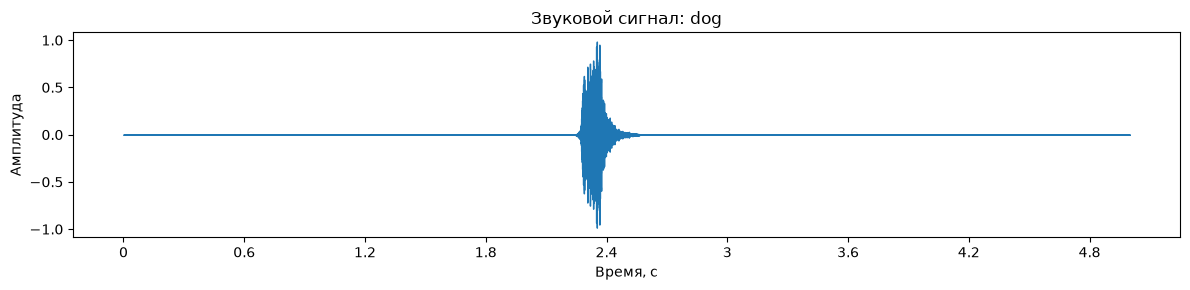

In [5]:
example = esc10.iloc[0]

example_audio, _ = librosa.load(
    os.path.join("audio", example["filename"]),
    sr=SAMPLE_RATE,
    mono=True
)

print("Класс:", example["category"])
print("Файл:", example["filename"])

display(
    Audio(example_audio, rate=SAMPLE_RATE)
)

plt.figure(figsize=(12, 3))

librosa.display.waveshow(
    example_audio,
    sr=SAMPLE_RATE
)

plt.title(f"Звуковой сигнал: {example['category']}")
plt.xlabel("Время, с")
plt.ylabel("Амплитуда")

plt.tight_layout()
plt.show()

In [6]:
def load_audio(filename):
    audio, _ = librosa.load(
        os.path.join("audio", filename),
        sr=SAMPLE_RATE,
        mono=True
    )

    if len(audio) < AUDIO_LENGTH:
        audio = np.pad(
            audio,
            (0, AUDIO_LENGTH - len(audio))
        )
    else:
        audio = audio[:AUDIO_LENGTH]

    return audio.astype(np.float32)


def extract_features(audio):
    mfcc = librosa.feature.mfcc(
        y=audio,
        sr=SAMPLE_RATE,
        n_mfcc=20
    )

    spectral_centroid = librosa.feature.spectral_centroid(
        y=audio,
        sr=SAMPLE_RATE
    )

    spectral_bandwidth = librosa.feature.spectral_bandwidth(
        y=audio,
        sr=SAMPLE_RATE
    )

    spectral_rolloff = librosa.feature.spectral_rolloff(
        y=audio,
        sr=SAMPLE_RATE
    )

    zero_crossing = librosa.feature.zero_crossing_rate(audio)

    rms = librosa.feature.rms(y=audio)

    features = np.concatenate([
        mfcc.mean(axis=1),
        mfcc.std(axis=1),

        spectral_centroid.mean(axis=1),
        spectral_centroid.std(axis=1),

        spectral_bandwidth.mean(axis=1),
        spectral_bandwidth.std(axis=1),

        spectral_rolloff.mean(axis=1),
        spectral_rolloff.std(axis=1),

        zero_crossing.mean(axis=1),
        zero_crossing.std(axis=1),

        rms.mean(axis=1),
        rms.std(axis=1)
    ])

    return features.astype(np.float32)


def make_mel_spectrogram(audio):
    mel = librosa.feature.melspectrogram(
        y=audio,
        sr=SAMPLE_RATE,
        n_fft=1024,
        hop_length=256,
        n_mels=64,
        power=2.0
    )

    mel_db = librosa.power_to_db(
        mel,
        ref=np.max
    )

    mel_normalized = np.clip(
        (mel_db + 80.0) / 80.0,
        0.0,
        1.0
    )

    return mel_normalized.astype(np.float32)

In [7]:
waveforms = []
feature_vectors = []
spectrograms = []
labels = []

for _, row in tqdm(
    esc10.iterrows(),
    total=len(esc10),
    desc="Обработка аудиозаписей"
):
    audio = load_audio(row["filename"])

    waveforms.append(audio)
    feature_vectors.append(extract_features(audio))
    spectrograms.append(make_mel_spectrogram(audio))
    labels.append(row["label"])


X_wave = np.stack(waveforms)
X_features = np.stack(feature_vectors)
X_mel = np.stack(spectrograms)

y = np.array(
    labels,
    dtype=np.int64
)

print("\nВременные сигналы:", X_wave.shape)
print("Признаки звука:", X_features.shape)
print("Мел-спектрограммы:", X_mel.shape)
print("Метки классов:", y.shape)

Обработка аудиозаписей: 100%|██████████| 400/400 [00:05<00:00, 77.36it/s]


Временные сигналы: (400, 80000)
Признаки звука: (400, 50)
Мел-спектрограммы: (400, 64, 313)
Метки классов: (400,)


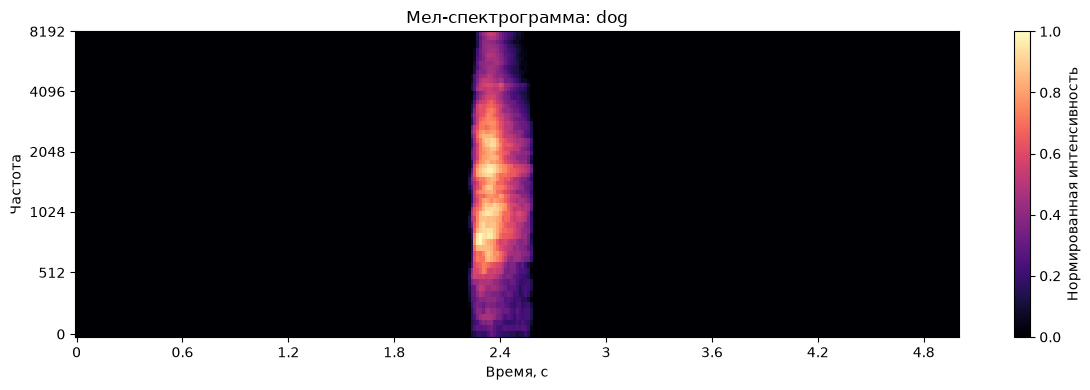

In [8]:
plt.figure(figsize=(12, 4))

librosa.display.specshow(
    X_mel[0],
    sr=SAMPLE_RATE,
    hop_length=256,
    x_axis="time",
    y_axis="mel"
)

plt.colorbar(
    label="Нормированная интенсивность"
)

plt.title(
    f"Мел-спектрограмма: {esc10.iloc[0]['category']}"
)

plt.xlabel("Время, с")
plt.ylabel("Частота")

plt.tight_layout()
plt.show()

In [9]:
folds = esc10["fold"].to_numpy()

train_idx = np.where(
    np.isin(folds, [1, 2, 3])
)[0]

val_idx = np.where(
    folds == 4
)[0]

test_idx = np.where(
    folds == 5
)[0]

print("Обучение:", len(train_idx))
print("Валидация:", len(val_idx))
print("Тест:", len(test_idx))

Обучение: 240
Валидация: 80
Тест: 80


In [10]:
scaler = StandardScaler()

X_features_scaled = np.empty_like(
    X_features,
    dtype=np.float32
)

X_features_scaled[train_idx] = scaler.fit_transform(
    X_features[train_idx]
)

X_features_scaled[val_idx] = scaler.transform(
    X_features[val_idx]
)

X_features_scaled[test_idx] = scaler.transform(
    X_features[test_idx]
)

In [11]:
def make_loaders(X, y, train_idx, val_idx, test_idx):
    X_tensor = torch.tensor(
        X,
        dtype=torch.float32
    )

    y_tensor = torch.tensor(
        y,
        dtype=torch.long
    )

    train_dataset = TensorDataset(
        X_tensor[train_idx],
        y_tensor[train_idx]
    )

    val_dataset = TensorDataset(
        X_tensor[val_idx],
        y_tensor[val_idx]
    )

    test_dataset = TensorDataset(
        X_tensor[test_idx],
        y_tensor[test_idx]
    )

    generator = torch.Generator()
    generator.manual_seed(SEED)

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    return train_loader, val_loader, test_loader

In [12]:
mlp_loaders = make_loaders(
    X_features_scaled,
    y,
    train_idx,
    val_idx,
    test_idx
)

wave_loaders = make_loaders(
    X_wave[:, np.newaxis, :],
    y,
    train_idx,
    val_idx,
    test_idx
)

mel_loaders = make_loaders(
    X_mel[:, np.newaxis, :, :],
    y,
    train_idx,
    val_idx,
    test_idx
)

In [13]:
class MLPClassifier(nn.Module):
    def __init__(self, n_features, n_classes):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(n_features, 128),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(64, n_classes)
        )

    def forward(self, x):
        return self.network(x)

In [14]:
class WaveformCNN(nn.Module):
    def __init__(self, n_classes):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv1d(
                1,
                16,
                kernel_size=80,
                stride=16,
                padding=32
            ),
            nn.BatchNorm1d(16),
            nn.ReLU(),
            nn.MaxPool1d(4),

            nn.Conv1d(
                16,
                32,
                kernel_size=9,
                padding=4
            ),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(4),

            nn.Conv1d(
                32,
                64,
                kernel_size=5,
                padding=2
            ),
            nn.BatchNorm1d(64),
            nn.ReLU(),

            nn.AdaptiveAvgPool1d(1)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(64, n_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

In [15]:
class SpectrogramCNN(nn.Module):
    def __init__(self, n_classes):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(
                1,
                16,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(
                16,
                32,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(
                32,
                64,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(64, n_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

In [16]:
def train_model(model, train_loader, val_loader):
    model = model.to(DEVICE)

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE
    )

    best_val_loss = float("inf")
    best_state = None
    bad_epochs = 0

    history = {
        "train_loss": [],
        "val_loss": [],
        "val_accuracy": []
    }

    for epoch in range(EPOCHS):
        model.train()
        train_loss = 0.0

        for batch_x, batch_y in train_loader:
            batch_x = batch_x.to(DEVICE)
            batch_y = batch_y.to(DEVICE)

            optimizer.zero_grad()

            logits = model(batch_x)
            loss = criterion(logits, batch_y)

            loss.backward()
            optimizer.step()

            train_loss += loss.item() * len(batch_x)

        train_loss /= len(train_loader.dataset)

        model.eval()
        val_loss = 0.0

        val_predictions = []
        val_targets = []

        with torch.no_grad():
            for batch_x, batch_y in val_loader:
                batch_x = batch_x.to(DEVICE)
                batch_y = batch_y.to(DEVICE)

                logits = model(batch_x)
                loss = criterion(logits, batch_y)

                val_loss += loss.item() * len(batch_x)

                val_predictions.extend(
                    logits.argmax(dim=1).cpu().numpy()
                )

                val_targets.extend(
                    batch_y.cpu().numpy()
                )

        val_loss /= len(val_loader.dataset)

        val_accuracy = accuracy_score(
            val_targets,
            val_predictions
        )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_accuracy)

        print(
            f"Эпоха {epoch + 1:02d}/{EPOCHS} | "
            f"train loss: {train_loss:.4f} | "
            f"val loss: {val_loss:.4f} | "
            f"val accuracy: {val_accuracy:.4f}"
        )

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            bad_epochs = 0

        else:
            bad_epochs += 1

            if bad_epochs >= PATIENCE:
                print("Ранняя остановка.")
                break

    model.load_state_dict(best_state)

    return model, history

In [17]:
mlp_model = MLPClassifier(
    n_features=X_features_scaled.shape[1],
    n_classes=NUM_CLASSES
)

mlp_model, mlp_history = train_model(
    mlp_model,
    mlp_loaders[0],
    mlp_loaders[1]
)

Эпоха 01/35 | train loss: 2.2467 | val loss: 2.1217 | val accuracy: 0.3500
Эпоха 02/35 | train loss: 2.0404 | val loss: 1.8983 | val accuracy: 0.4625
Эпоха 03/35 | train loss: 1.7681 | val loss: 1.6236 | val accuracy: 0.5625
Эпоха 04/35 | train loss: 1.5258 | val loss: 1.3791 | val accuracy: 0.6125
Эпоха 05/35 | train loss: 1.3166 | val loss: 1.1695 | val accuracy: 0.7375
Эпоха 06/35 | train loss: 1.1425 | val loss: 1.0071 | val accuracy: 0.7750
Эпоха 07/35 | train loss: 1.0262 | val loss: 0.8867 | val accuracy: 0.8000
Эпоха 08/35 | train loss: 0.8826 | val loss: 0.7829 | val accuracy: 0.8250
Эпоха 09/35 | train loss: 0.8127 | val loss: 0.7062 | val accuracy: 0.8625
Эпоха 10/35 | train loss: 0.7189 | val loss: 0.6541 | val accuracy: 0.8500
Эпоха 11/35 | train loss: 0.6371 | val loss: 0.5903 | val accuracy: 0.8625
Эпоха 12/35 | train loss: 0.6554 | val loss: 0.5501 | val accuracy: 0.8500
Эпоха 13/35 | train loss: 0.5800 | val loss: 0.5275 | val accuracy: 0.8875
Эпоха 14/35 | train loss:

In [18]:
wave_model = WaveformCNN(
    n_classes=NUM_CLASSES
)

wave_model, wave_history = train_model(
    wave_model,
    wave_loaders[0],
    wave_loaders[1]
)

Эпоха 01/35 | train loss: 2.0876 | val loss: 2.3365 | val accuracy: 0.1000
Эпоха 02/35 | train loss: 1.8886 | val loss: 2.2623 | val accuracy: 0.1000
Эпоха 03/35 | train loss: 1.7717 | val loss: 1.9181 | val accuracy: 0.3375
Эпоха 04/35 | train loss: 1.6740 | val loss: 1.7552 | val accuracy: 0.4750
Эпоха 05/35 | train loss: 1.5917 | val loss: 1.6134 | val accuracy: 0.5500
Эпоха 06/35 | train loss: 1.5434 | val loss: 1.5499 | val accuracy: 0.6250
Эпоха 07/35 | train loss: 1.4644 | val loss: 1.4886 | val accuracy: 0.5875
Эпоха 08/35 | train loss: 1.3784 | val loss: 1.4001 | val accuracy: 0.6250
Эпоха 09/35 | train loss: 1.3213 | val loss: 1.3938 | val accuracy: 0.6500
Эпоха 10/35 | train loss: 1.3116 | val loss: 1.3163 | val accuracy: 0.6625
Эпоха 11/35 | train loss: 1.2791 | val loss: 1.3306 | val accuracy: 0.5625
Эпоха 12/35 | train loss: 1.2250 | val loss: 1.2990 | val accuracy: 0.6000
Эпоха 13/35 | train loss: 1.2066 | val loss: 1.2539 | val accuracy: 0.6375
Эпоха 14/35 | train loss:

In [19]:
mel_model = SpectrogramCNN(
    n_classes=NUM_CLASSES
)

mel_model, mel_history = train_model(
    mel_model,
    mel_loaders[0],
    mel_loaders[1]
)

Эпоха 01/35 | train loss: 2.0897 | val loss: 2.2348 | val accuracy: 0.2875
Эпоха 02/35 | train loss: 1.8399 | val loss: 2.0486 | val accuracy: 0.3000
Эпоха 03/35 | train loss: 1.7079 | val loss: 1.8463 | val accuracy: 0.2875
Эпоха 04/35 | train loss: 1.6547 | val loss: 1.6462 | val accuracy: 0.4125
Эпоха 05/35 | train loss: 1.5604 | val loss: 1.5462 | val accuracy: 0.5125
Эпоха 06/35 | train loss: 1.4889 | val loss: 1.4760 | val accuracy: 0.5000
Эпоха 07/35 | train loss: 1.4036 | val loss: 1.4195 | val accuracy: 0.6125
Эпоха 08/35 | train loss: 1.3964 | val loss: 1.3548 | val accuracy: 0.5000
Эпоха 09/35 | train loss: 1.3973 | val loss: 1.4271 | val accuracy: 0.4000
Эпоха 10/35 | train loss: 1.3401 | val loss: 1.2527 | val accuracy: 0.6250
Эпоха 11/35 | train loss: 1.2959 | val loss: 1.2466 | val accuracy: 0.6500
Эпоха 12/35 | train loss: 1.2776 | val loss: 1.2606 | val accuracy: 0.5875
Эпоха 13/35 | train loss: 1.1480 | val loss: 1.2289 | val accuracy: 0.5500
Эпоха 14/35 | train loss:

In [20]:
def evaluate_model(model, test_loader):
    model.eval()

    all_predictions = []
    all_targets = []

    with torch.no_grad():
        for batch_x, batch_y in test_loader:
            batch_x = batch_x.to(DEVICE)

            logits = model(batch_x)

            predictions = (
                logits.argmax(dim=1)
                .cpu()
                .numpy()
            )

            all_predictions.extend(predictions)
            all_targets.extend(batch_y.numpy())

    return {
        "accuracy": accuracy_score(
            all_targets,
            all_predictions
        ),

        "macro_f1": f1_score(
            all_targets,
            all_predictions,
            average="macro",
            zero_division=0
        ),

        "targets": np.array(all_targets),
        "predictions": np.array(all_predictions)
    }


mlp_result = evaluate_model(
    mlp_model,
    mlp_loaders[2]
)

wave_result = evaluate_model(
    wave_model,
    wave_loaders[2]
)

mel_result = evaluate_model(
    mel_model,
    mel_loaders[2]
)

In [21]:
results = pd.DataFrame([
    {
        "Модель": "MLP — признаки",
        "Accuracy": mlp_result["accuracy"],
        "Macro F1": mlp_result["macro_f1"]
    },
    {
        "Модель": "1D-CNN — сигнал",
        "Accuracy": wave_result["accuracy"],
        "Macro F1": wave_result["macro_f1"]
    },
    {
        "Модель": "2D-CNN — мел-спектрограмма",
        "Accuracy": mel_result["accuracy"],
        "Macro F1": mel_result["macro_f1"]
    }
])

results = results.sort_values(
    "Accuracy",
    ascending=False
).reset_index(drop=True)

display(results)

,Модель,Accuracy,Macro F1
0,MLP — признаки,0.8125,0.804472
1,1D-CNN — сигнал,0.7000,0.699405
2,2D-CNN — мел-спектрограмма,0.6500,0.609791


In [22]:
model_results = {
    "MLP — признаки": mlp_result,
    "1D-CNN — сигнал": wave_result,
    "2D-CNN — мел-спектрограмма": mel_result
}

best_model_name = results.iloc[0]["Модель"]
best_result = model_results[best_model_name]

print("Лучшая модель на тестовом фолде:", best_model_name)

print(
    classification_report(
        best_result["targets"],
        best_result["predictions"],
        labels=np.arange(NUM_CLASSES),
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

Лучшая модель на тестовом фолде: MLP — признаки
                precision    recall  f1-score   support

      chainsaw       1.00      0.88      0.93         8
    clock_tick       0.75      0.38      0.50         8
crackling_fire       1.00      0.50      0.67         8
   crying_baby       0.78      0.88      0.82         8
           dog       0.58      0.88      0.70         8
    helicopter       0.73      1.00      0.84         8
          rain       0.80      1.00      0.89         8
       rooster       1.00      0.88      0.93         8
     sea_waves       1.00      0.88      0.93         8
      sneezing       0.78      0.88      0.82         8

      accuracy                           0.81        80
     macro avg       0.84      0.81      0.80        80
  weighted avg       0.84      0.81      0.80        80



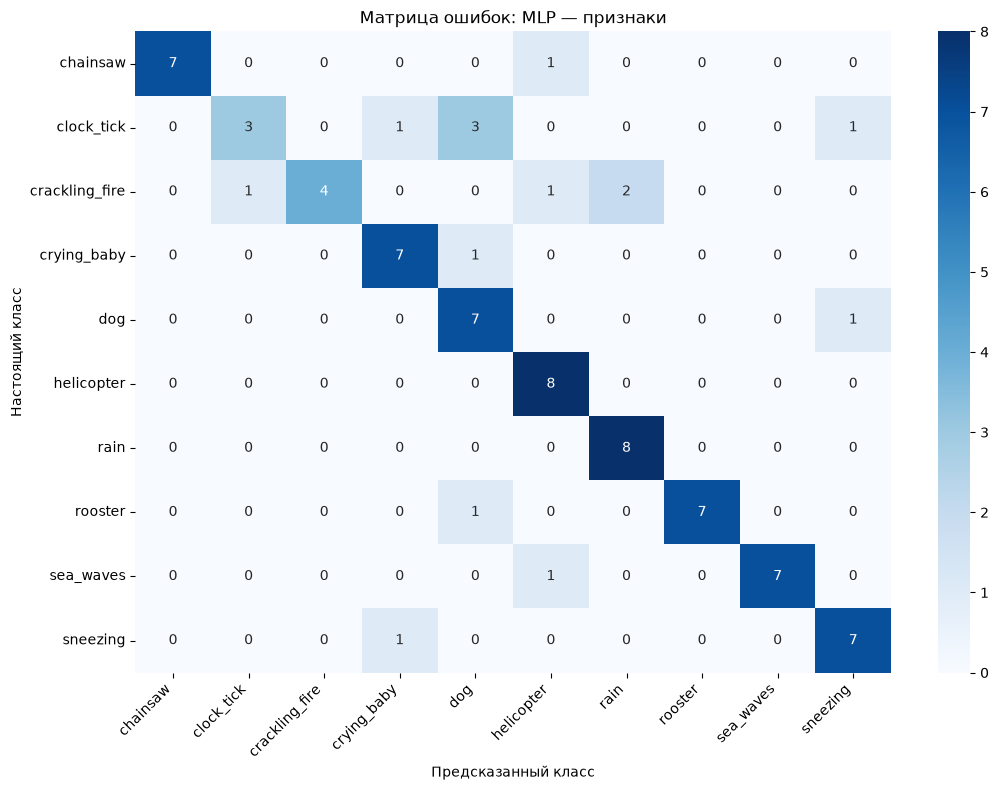

In [23]:
cm = confusion_matrix(
    best_result["targets"],
    best_result["predictions"],
    labels=np.arange(NUM_CLASSES)
)

plt.figure(figsize=(11, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title(f"Матрица ошибок: {best_model_name}")
plt.xlabel("Предсказанный класс")
plt.ylabel("Настоящий класс")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [24]:
from sklearn.svm import SVC

svm_model = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale"
)

svm_model.fit(
    X_features_scaled[train_idx],
    y[train_idx]
)

svm_pred = svm_model.predict(
    X_features_scaled[test_idx]
)

svm_result = {
    "accuracy": accuracy_score(
        y[test_idx],
        svm_pred
    ),
    "macro_f1": f1_score(
        y[test_idx],
        svm_pred,
        average="macro",
        zero_division=0
    ),
    "targets": y[test_idx].copy(),
    "predictions": svm_pred
}

print("SVM")
print("Accuracy:", round(svm_result["accuracy"], 4))
print("Macro F1:", round(svm_result["macro_f1"], 4))

SVM
Accuracy: 0.8375
Macro F1: 0.8312


In [25]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=SEED,
    n_jobs=-1
)

rf_model.fit(
    X_features[train_idx],
    y[train_idx]
)

rf_pred = rf_model.predict(
    X_features[test_idx]
)

rf_result = {
    "accuracy": accuracy_score(
        y[test_idx],
        rf_pred
    ),
    "macro_f1": f1_score(
        y[test_idx],
        rf_pred,
        average="macro",
        zero_division=0
    ),
    "targets": y[test_idx].copy(),
    "predictions": rf_pred
}

print("Random Forest")
print("Accuracy:", round(rf_result["accuracy"], 4))
print("Macro F1:", round(rf_result["macro_f1"], 4))

Random Forest
Accuracy: 0.85
Macro F1: 0.844


In [26]:
class CNNLSTMClassifier(nn.Module):
    def __init__(self, n_classes):
        super().__init__()

        self.cnn = nn.Sequential(
            nn.Conv2d(
                1,
                16,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(
                16,
                32,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.lstm = nn.LSTM(
            input_size=32,
            hidden_size=64,
            batch_first=True
        )

        self.classifier = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(64, n_classes)
        )

    def forward(self, x):
        # x: [batch, 1, частоты, время]
        x = self.cnn(x)

        # Усредняем признаки по частотной оси
        x = x.mean(dim=2)

        # [batch, каналы, время] → [batch, время, каналы]
        x = x.transpose(1, 2)

        _, (hidden, _) = self.lstm(x)

        # Последнее скрытое состояние LSTM
        x = hidden[-1]

        return self.classifier(x)

In [27]:
cnn_lstm_model = CNNLSTMClassifier(
    n_classes=NUM_CLASSES
)

cnn_lstm_model, cnn_lstm_history = train_model(
    cnn_lstm_model,
    mel_loaders[0],
    mel_loaders[1]
)

Эпоха 01/35 | train loss: 2.2180 | val loss: 2.2580 | val accuracy: 0.1500
Эпоха 02/35 | train loss: 2.0105 | val loss: 2.0239 | val accuracy: 0.3000
Эпоха 03/35 | train loss: 1.8586 | val loss: 1.8321 | val accuracy: 0.3375
Эпоха 04/35 | train loss: 1.7181 | val loss: 1.7202 | val accuracy: 0.3625
Эпоха 05/35 | train loss: 1.6141 | val loss: 1.6077 | val accuracy: 0.3375
Эпоха 06/35 | train loss: 1.6523 | val loss: 1.5993 | val accuracy: 0.4125
Эпоха 07/35 | train loss: 1.5880 | val loss: 1.6226 | val accuracy: 0.3875
Эпоха 08/35 | train loss: 1.5416 | val loss: 1.8885 | val accuracy: 0.2875
Эпоха 09/35 | train loss: 1.4590 | val loss: 1.5818 | val accuracy: 0.3250
Эпоха 10/35 | train loss: 1.5102 | val loss: 1.5814 | val accuracy: 0.3750
Эпоха 11/35 | train loss: 1.4588 | val loss: 1.4590 | val accuracy: 0.3750
Эпоха 12/35 | train loss: 1.4811 | val loss: 1.4828 | val accuracy: 0.4625
Эпоха 13/35 | train loss: 1.4790 | val loss: 1.4948 | val accuracy: 0.4500
Эпоха 14/35 | train loss:

In [28]:
cnn_lstm_result = evaluate_model(
    cnn_lstm_model,
    mel_loaders[2]
)

print("CNN + LSTM")
print("Accuracy:", round(cnn_lstm_result["accuracy"], 4))
print("Macro F1:", round(cnn_lstm_result["macro_f1"], 4))

CNN + LSTM
Accuracy: 0.475
Macro F1: 0.442


In [29]:
import torch.nn.functional as F

from torchvision.models import (
    resnet18,
    ResNet18_Weights
)


class ResNetAudioClassifier(nn.Module):
    def __init__(self, n_classes):
        super().__init__()

        self.backbone = resnet18(
            weights=ResNet18_Weights.DEFAULT
        )

        for parameter in self.backbone.parameters():
            parameter.requires_grad = False

        in_features = self.backbone.fc.in_features

        self.backbone.fc = nn.Linear(
            in_features,
            n_classes
        )

        self.register_buffer(
            "image_mean",
            torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
        )

        self.register_buffer(
            "image_std",
            torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
        )

    def train(self, mode=True):
        super().train(mode)

        # Замороженная основа остаётся в режиме оценки,
        # чтобы не менять статистики BatchNorm
        self.backbone.eval()
        self.backbone.fc.train(mode)

        return self

    def forward(self, x):
        # Одноканальная спектрограмма → 3 одинаковых канала
        x = x.repeat(1, 3, 1, 1)

        x = F.interpolate(
            x,
            size=(224, 224),
            mode="bilinear",
            align_corners=False
        )

        x = (x - self.image_mean) / self.image_std

        return self.backbone(x)

In [30]:
resnet_model = ResNetAudioClassifier(
    n_classes=NUM_CLASSES
)

resnet_model, resnet_history = train_model(
    resnet_model,
    mel_loaders[0],
    mel_loaders[1]
)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /home/mlguest/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:04<00:00, 10.7MB/s]


Эпоха 01/35 | train loss: 2.1584 | val loss: 1.8019 | val accuracy: 0.4000
Эпоха 02/35 | train loss: 1.5883 | val loss: 1.3987 | val accuracy: 0.7250
Эпоха 03/35 | train loss: 1.2432 | val loss: 1.1616 | val accuracy: 0.7625
Эпоха 04/35 | train loss: 1.0202 | val loss: 0.9887 | val accuracy: 0.8250
Эпоха 05/35 | train loss: 0.8703 | val loss: 0.8953 | val accuracy: 0.8000
Эпоха 06/35 | train loss: 0.7645 | val loss: 0.8018 | val accuracy: 0.8250
Эпоха 07/35 | train loss: 0.6757 | val loss: 0.7525 | val accuracy: 0.8125
Эпоха 08/35 | train loss: 0.6131 | val loss: 0.6943 | val accuracy: 0.8250
Эпоха 09/35 | train loss: 0.5710 | val loss: 0.6615 | val accuracy: 0.8125
Эпоха 10/35 | train loss: 0.5206 | val loss: 0.6287 | val accuracy: 0.8375
Эпоха 11/35 | train loss: 0.4824 | val loss: 0.6053 | val accuracy: 0.8250
Эпоха 12/35 | train loss: 0.4476 | val loss: 0.5888 | val accuracy: 0.8125
Эпоха 13/35 | train loss: 0.4178 | val loss: 0.5620 | val accuracy: 0.8250
Эпоха 14/35 | train loss:

In [31]:
resnet_result = evaluate_model(
    resnet_model,
    mel_loaders[2]
)

print("ResNet18")
print("Accuracy:", round(resnet_result["accuracy"], 4))
print("Macro F1:", round(resnet_result["macro_f1"], 4))

ResNet18
Accuracy: 0.8625
Macro F1: 0.8634


In [32]:
from transformers import (
    AutoFeatureExtractor,
    ASTModel
)

AST_MODEL_NAME = "MIT/ast-finetuned-audioset-10-10-0.4593"

ast_extractor = AutoFeatureExtractor.from_pretrained(
    AST_MODEL_NAME
)

ast_model = ASTModel.from_pretrained(
    AST_MODEL_NAME
).to(DEVICE)

ast_model.eval()

for parameter in ast_model.parameters():
    parameter.requires_grad = False

print("AST загружена:", AST_MODEL_NAME)
print("Размер эмбеддинга:", ast_model.config.hidden_size)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 18555.98it/s]
[transformers] ASTModel LOAD REPORT from: MIT/ast-finetuned-audioset-10-10-0.4593
Key                         | Status     |  | 
----------------------------+------------+--+-
classifier.dense.weight     | UNEXPECTED |  | 
classifier.layernorm.weight | UNEXPECTED |  | 
classifier.layernorm.bias   | UNEXPECTED |  | 
classifier.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


AST загружена: MIT/ast-finetuned-audioset-10-10-0.4593
Размер эмбеддинга: 768


In [33]:
ast_embeddings = []

AST_BATCH_SIZE = 4

with torch.inference_mode():
    for start in tqdm(
        range(0, len(X_wave), AST_BATCH_SIZE),
        desc="Извлечение эмбеддингов AST"
    ):
        batch_audio = [
            audio
            for audio in X_wave[start:start + AST_BATCH_SIZE]
        ]

        inputs = ast_extractor(
            batch_audio,
            sampling_rate=SAMPLE_RATE,
            return_tensors="pt",
            padding=True
        )

        inputs = {
            key: value.to(DEVICE)
            for key, value in inputs.items()
        }

        outputs = ast_model(**inputs)

        # Первый токен используется как представление записи
        embeddings = outputs.last_hidden_state[:, 0, :]

        ast_embeddings.append(
            embeddings.cpu().numpy()
        )

        del inputs, outputs, embeddings

X_ast = np.concatenate(
    ast_embeddings,
    axis=0
)

print("Форма эмбеддингов AST:", X_ast.shape)

Извлечение эмбеддингов AST: 100%|██████████| 100/100 [00:07<00:00, 12.53it/s]

Форма эмбеддингов AST: (400, 768)


In [34]:
del ast_model

if torch.cuda.is_available():
    torch.cuda.empty_cache()

In [35]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

ast_classifier = make_pipeline(
    StandardScaler(),
    SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale"
    )
)

ast_classifier.fit(
    X_ast[train_idx],
    y[train_idx]
)

ast_pred = ast_classifier.predict(
    X_ast[test_idx]
)

ast_result = {
    "accuracy": accuracy_score(
        y[test_idx],
        ast_pred
    ),
    "macro_f1": f1_score(
        y[test_idx],
        ast_pred,
        average="macro",
        zero_division=0
    ),
    "targets": y[test_idx].copy(),
    "predictions": ast_pred
}

print("AST + SVM")
print("Accuracy:", round(ast_result["accuracy"], 4))
print("Macro F1:", round(ast_result["macro_f1"], 4))

AST + SVM
Accuracy: 0.975
Macro F1: 0.9756


In [36]:
all_model_results = {
    "MLP — признаки": mlp_result,
    "1D-CNN — сигнал": wave_result,
    "2D-CNN — спектрограмма": mel_result,
    "SVM — признаки": svm_result,
    "Random Forest — признаки": rf_result,
    "CNN + LSTM — спектрограмма": cnn_lstm_result,
    "ResNet18 — предобученная": resnet_result,
    "AST + SVM — предобученная": ast_result
}

comparison = pd.DataFrame([
    {
        "Модель": name,
        "Accuracy": result["accuracy"],
        "Macro F1": result["macro_f1"]
    }
    for name, result in all_model_results.items()
])

comparison = comparison.sort_values(
    "Accuracy",
    ascending=False
).reset_index(drop=True)

display(comparison)

,Модель,Accuracy,Macro F1
0,AST + SVM — предобученная,0.9750,0.975556
1,ResNet18 — предобученная,0.8625,0.863394
2,Random Forest — признаки,0.8500,0.844050
3,SVM — признаки,0.8375,0.831220
4,MLP — признаки,0.8125,0.804472
5,1D-CNN — сигнал,0.7000,0.699405
6,2D-CNN — спектрограмма,0.6500,0.609791
7,CNN + LSTM — спектрограмма,0.4750,0.442016


Модель: SVM — признаки
                precision    recall  f1-score   support

      chainsaw       1.00      0.62      0.77         8
    clock_tick       0.86      0.75      0.80         8
crackling_fire       1.00      0.50      0.67         8
   crying_baby       0.80      1.00      0.89         8
           dog       0.88      0.88      0.88         8
    helicopter       0.80      1.00      0.89         8
          rain       0.80      1.00      0.89         8
       rooster       1.00      0.88      0.93         8
     sea_waves       0.78      0.88      0.82         8
      sneezing       0.70      0.88      0.78         8

      accuracy                           0.84        80
     macro avg       0.86      0.84      0.83        80
  weighted avg       0.86      0.84      0.83        80



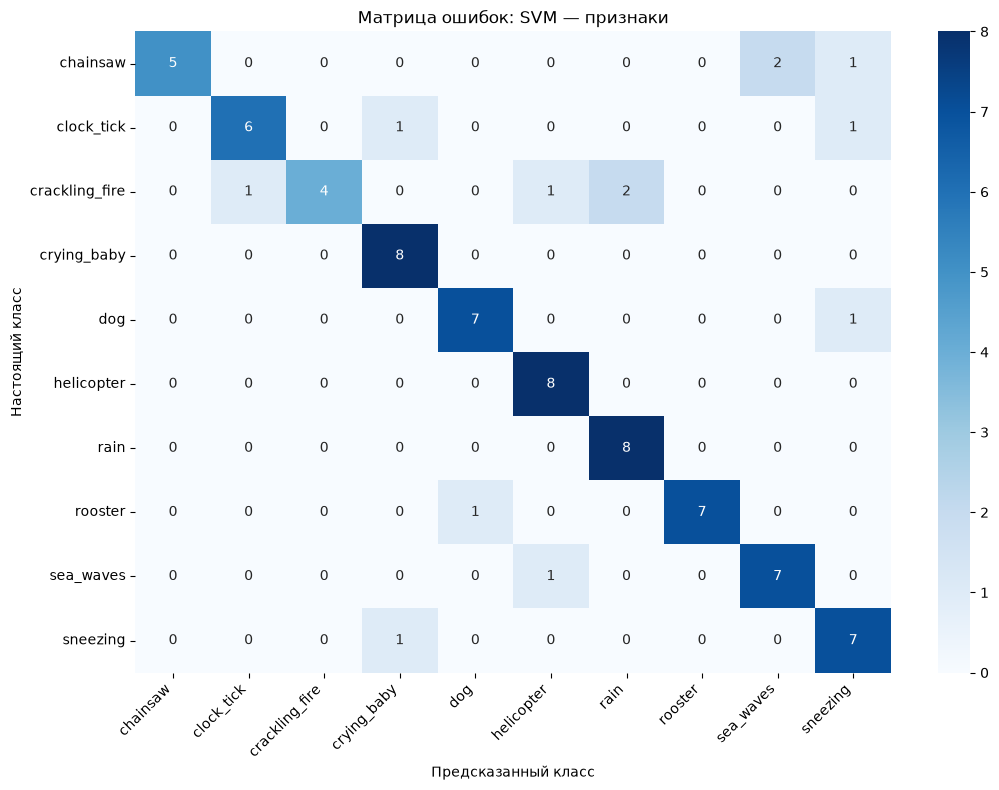

In [37]:
model_name = "SVM — признаки"

result = all_model_results[model_name]

print("Модель:", model_name)

print(
    classification_report(
        result["targets"],
        result["predictions"],
        labels=np.arange(NUM_CLASSES),
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

cm = confusion_matrix(
    result["targets"],
    result["predictions"],
    labels=np.arange(NUM_CLASSES)
)

plt.figure(figsize=(11, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title(f"Матрица ошибок: {model_name}")
plt.xlabel("Предсказанный класс")
plt.ylabel("Настоящий класс")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [38]:
ast_errors = esc10.iloc[test_idx].copy().reset_index(drop=True)

ast_errors["true_class"] = label_encoder.inverse_transform(
    ast_result["targets"]
)

ast_errors["predicted_class"] = label_encoder.inverse_transform(
    ast_result["predictions"]
)

ast_errors = ast_errors[
    ast_errors["true_class"] != ast_errors["predicted_class"]
].copy()

print("Количество ошибок:", len(ast_errors))

display(
    ast_errors[[
        "filename",
        "true_class",
        "predicted_class",
        "fold"
    ]]
)

Количество ошибок: 2


,filename,true_class,predicted_class,fold
57,5-213802-A-12.wav,crackling_fire,helicopter,5
73,5-222524-A-41.wav,chainsaw,helicopter,5
